In [1]:
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
from src.util import *
from src.config import *
from src.preprocess import *

## 0. 데이터 로드

In [2]:
data_path = "dataset/processed/csv/"
all_df = []
filelst = os.listdir(data_path)
for i in (filelst):
    df = pd.read_csv(data_path+i)
    df["Boundary"] = 1
    df.loc[df["vel_mag"]==0,"Boundary"]=0
    all_df.append(df)

## 1. Boundary condition 생성

In [3]:
df = all_df[0].copy()

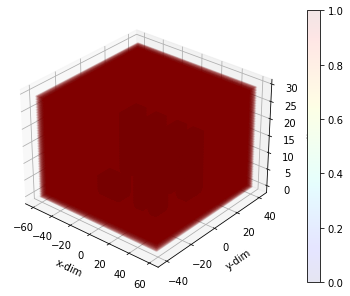

In [4]:
# plotting
min_vel_mag = min(df["Boundary"])
max_vel_mag = max(df["Boundary"])
setting_lst = [10,5,3,0.1,min_vel_mag,max_vel_mag,30,310]
plotting(df,df["Boundary"],setting_lst)

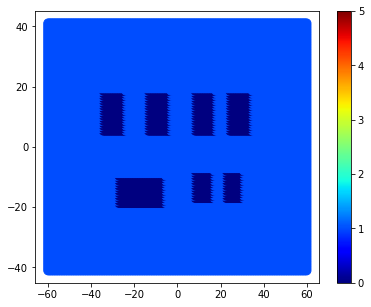

In [5]:
## 단면으로 결과확인 (z 고정)

position_z = 5
default_z = sorted(list(set(df["z"]))) # 고정될 z값 (xy 단면을 보기위해)
condition_z = df["z"]==default_z[position_z] # z 조건 정의
x = df[condition_z]["x"]
y = df[condition_z]["y"]
plot_data = df[condition_z]["Boundary"]

plt.figure(figsize=[14,5])
plt.subplot(1,2,1)
plt.scatter(x,y,c=plot_data, marker="o", s=80, cmap='jet', label="Label", vmin=0, vmax=5)
plt.colorbar()

In [6]:
# 1. 벽면 2로 칠함
poslist = ["x","y","z"]
for i in poslist:
    df.loc[df[i]==np.min(df[i]),"Boundary"]=2
    df.loc[df[i]==np.max(df[i]),"Boundary"]=2

# 2. 입/출구 지정
poslist = ["y"]
for i in poslist:
    df.loc[df[i]==np.min(df[i]),"Boundary"]=3
    df.loc[df[i]==np.max(df[i]),"Boundary"]=4

In [7]:
min_vel_mag = min(df["Boundary"])
max_vel_mag = max(df["Boundary"])

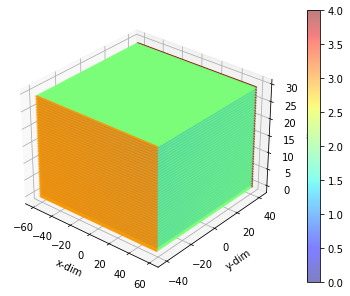

In [8]:
# 입구확인
setting_lst = [10,5,3,0.5,min_vel_mag,max_vel_mag,30,310]
plotting(df,df["Boundary"],setting_lst)

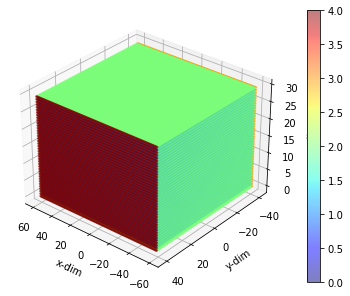

In [9]:
# 출구확인
setting_lst = [10,5,3,0.5,min_vel_mag,max_vel_mag,30,130]
plotting(df,df["Boundary"],setting_lst)

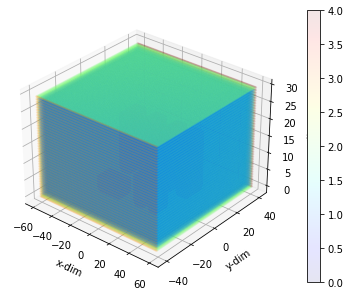

In [10]:
# 내부확인
setting_lst = [10,5,3,0.1,min_vel_mag,max_vel_mag,30,310]
plotting(df,df["Boundary"],setting_lst)

In [11]:
np.save('dataset/processed/input/boundary/boundary_condition.npy',df["Boundary"].values)

## 2. 운전조건 생성

In [1]:
from src.generate_operating_condition import *

In [2]:
char2idx, idx2char = generate_operating_condition()

[['<inlet_velocity> 0.25 <NONE> 0'], ['<inlet_velocity> 0.5 <NONE> 0'], ['<inlet_velocity> 0.75 <NONE> 0'], ['<inlet_velocity> 1 <NONE> 0'], ['<inlet_velocity> 1.25 <NONE> 0'], ['<inlet_velocity> 1.5 <NONE> 0'], ['<inlet_velocity> 1.75 <NONE> 0'], ['<inlet_velocity> 2 <NONE> 0'], ['<inlet_velocity> 2.25 <NONE> 0'], ['<inlet_velocity> 2.5 <NONE> 0'], ['<inlet_velocity> 2.75 <NONE> 0'], ['<inlet_velocity> 3 <NONE> 0'], ['<inlet_velocity> 3.25 <NONE> 0'], ['<inlet_velocity> 3.5 <NONE> 0'], ['<inlet_velocity> 3.75 <NONE> 0'], ['<inlet_velocity> 4 <NONE> 0'], ['<inlet_velocity> 4.25 <NONE> 0'], ['<inlet_velocity> 4.5 <NONE> 0'], ['<inlet_velocity> 4.75 <NONE> 0'], ['<inlet_velocity> 5 <NONE> 0']]


In [3]:
operating_condition = np.load('dataset/processed/input/operating/operating_condition.npy')
operating_condition

array([[ 0,  3,  1,  2],
       [ 0,  4,  1,  2],
       [ 0,  5,  1,  2],
       [ 0,  6,  1,  2],
       [ 0,  7,  1,  2],
       [ 0,  8,  1,  2],
       [ 0,  9,  1,  2],
       [ 0, 10,  1,  2],
       [ 0, 11,  1,  2],
       [ 0, 12,  1,  2],
       [ 0, 13,  1,  2],
       [ 0, 14,  1,  2],
       [ 0, 15,  1,  2],
       [ 0, 16,  1,  2],
       [ 0, 17,  1,  2],
       [ 0, 18,  1,  2],
       [ 0, 19,  1,  2],
       [ 0, 20,  1,  2],
       [ 0, 21,  1,  2],
       [ 0, 22,  1,  2]])

## 3. 레이블 데이터 생성

In [17]:
data_path = "dataset/processed/csv/"
all_df = []
filelst = os.listdir(data_path)
for i in (filelst):
    df = pd.read_csv(data_path+i)
    all_df.append(list(df["vel_mag"].values))
all_df = np.array(all_df)
np.save('dataset/processed/output/label.npy',all_df)